### Auto-segmentation of individual segments in scape data
The goal is to segment muscles inside individual segments (manually labeled on napari) for one scape dataset to then link to muscles in the reference

In [4]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import tifffile
import h5py
import scapeio
import tqdm

from scape_utils import load_voxel_size, load_proj
%matplotlib inline

import sys
sys.path.append(str(Path('/home/azcorra/git/Devel/Pupa_muscle_imaging')))
import utils

In [5]:
# set paths to data
main_path = Path('/mnt/labserver/data/MA/SCAPE/')
scape_path = main_path / '20260716_MA12_pupa-P15/sample2_combined'
h5_folder = scape_path / 'segment_masked_video'
h5_folder.mkdir(parents=True, exist_ok=True)

In [6]:
# Get projection image for scape data (and aspect_ratio for plotting)
proj = load_proj(scape_path, 'max_proj')
voxel_sizes = load_voxel_size(scape_path)
axes_order = list(voxel_sizes.keys())

aspect_ratio = [
    voxel_sizes[others[0]] / voxel_sizes[others[1]]
    for i, element in enumerate(axes_order)
    for others in [axes_order[:i] + axes_order[i+1:]]
]

### Load manual segment labels (from napari)

In [7]:
# load manual labels

from scipy import ndimage

segment_masks_path = scape_path / 'RLF-RLM_leg_segments.tif'
segment_masks = tifffile.imread(segment_masks_path)
segment_ids = {1:'LF_trochanter', 2:'LF_tibia', 3:'LF_femur', 4:'LF_coxa', 
               5:'LM_tibia', 6:'LM_femur', 7:'LM_coxa', 8:'LM_trochanter',
               9:'RF_trochanter', 10:'RF_tibia', 11:'RF_femur', 12:'RF_coxa',
               16:'RM_trochanter', 14:'RM_tibia', 15:'RM_femur', 13:'RM_coxa',}
# check that IDs are unique
assert len(segment_ids) == len(set(segment_ids.values()))

print(f'Segment shape: {segment_masks.shape}, proj shape {proj.shape}')
assert [i==j for i, j in zip(segment_masks.shape, proj.shape)]

# bounding box (one slice tuple per axis) for each segment's mask.
# find_objects returns boxes ordered by label value (index 0 = label 1, etc.),
# NOT by segment_ids' insertion order (which has 16 before 13/14/15) - so index
# by label value explicitly rather than zipping against segment_ids.keys().
all_bounding_boxes = ndimage.find_objects(segment_masks)
bounding_boxes = {i: all_bounding_boxes[i - 1] for i in segment_ids}

Segment shape: (336, 261, 1000), proj shape (336, 261, 1000)


In [8]:
for i in range(1,np.max(list(segment_ids.keys()))+1):
    print(f'{str(i).ljust(2)} - {segment_ids[i].ljust(14)}: {str(np.sum(segment_masks==i)).rjust(7)}')

1  - LF_trochanter :   72303
2  - LF_tibia      :  207508
3  - LF_femur      :  805979
4  - LF_coxa       : 1097553
5  - LM_tibia      :  386701
6  - LM_femur      :  484799
7  - LM_coxa       :  235877
8  - LM_trochanter :   98186
9  - RF_trochanter :   70726
10 - RF_tibia      :  235202
11 - RF_femur      :  858918
12 - RF_coxa       :  874174
13 - RM_coxa       :  222134
14 - RM_tibia      :  303118
15 - RM_femur      :  557113
16 - RM_trochanter :   80296


## Load already processed data (if it exists)

In [7]:
#selected_segments = [1,2,3,4,5,6,7,8]
selected_segments = [9,10,11,12,13,14,15,16]

In [ ]:
missing_ids = []
segment_video_flat = {}
segment_video_flat_norm = {}
selected_idx = {}
medians = {}
already_processed = True
for sid in selected_segments:

    print(sid, segment_ids[sid])
    try:
        video_h5_path = scape_path / 'segment_masked_video' / f'{segment_ids[sid]}_masked_flattened_video.h5'
        with h5py.File(video_h5_path, 'r') as f:
            segment_video_flat[sid] = f['segment_video_flat'][:]
            try:
                selected_idx[sid] = f['selected_idx'][:]
                medians[sid] = f['median'][:]
                segment_video_flat_norm[sid] = utils.diff_norm_frames(segment_video_flat[sid], medians[sid])
            except Exception as e:
                print(e)
                missing_ids.append(sid)

    except Exception as e:
        print(e)
        already_processed = False
        break

9 RF_trochanter
10 RF_tibia
11 RF_femur
12 RF_coxa
13 RM_coxa
14 RM_tibia
15 RM_femur
16 RM_trochanter


### Mask video for all individual segments (and save)

In [ ]:
# load videos in batches but keep only pixels in one segment
#(only if not already saved)

if not already_processed:

    from scape_utils import check_folder_structure, analysis_path_for, PROJECTION_FILE_NAME

    # initialize masked videos
    segment_video_flat = {sid: [] for sid in selected_segments}


    # get the runs combined into this sample_combined folder (see combine_sample_projections)
    with h5py.File(analysis_path_for(scape_path) / PROJECTION_FILE_NAME, 'r') as f:
        source_runs = list(f.attrs['source_runs'])
    print(f'Source runs for {scape_path.name}: {source_runs}')

    exp_folder = scape_path.parent
    batch_size = 50

    segment_video_parts = {sid: [] for sid in selected_segments}

    for run_name in source_runs:
        run_path = exp_folder / run_name
        check_folder_structure(run_path)
        scape_raw_path = str(run_path / run_path.name)
        _, num_volumes, _ = scapeio.get_scan_timing(scape_raw_path)


        for start_volume in tqdm.tqdm(range(0, num_volumes, batch_size), desc=f'Loading {run_name}'):
            end_volume = min(start_volume + batch_size, num_volumes)
            video_batch, _ = scapeio.load_scan(scape_raw_path, colors=1, start_volume=start_volume,
                                            end_volume=end_volume - 1, return_axis_order=True)
            deskewed_batch = scapeio.operations.deskew_scan(scape_raw_path, images=video_batch)
            del video_batch

            # keep only the segment's pixels, as a (n_volumes_in_batch, n_pixels) array
            for sid in selected_segments:

                segment_mask = segment_masks == sid
                segment_video_parts[sid].append(deskewed_batch[:, segment_mask].astype(np.float32))

            del deskewed_batch

    for sid in selected_segments:
        segment_video_flat[sid] = np.concatenate(segment_video_parts[sid], axis=0)

    del segment_video_parts

    print('')
    print('Done loading video and masking - saving...')
    print('')


    # save the masked, flattened video (in case next steps fail)
    for sid in selected_segments:
        print(f'{sid}: {segment_ids[sid]}...')
        video_h5_path = h5_folder / f'{segment_ids[sid]}_masked_flattened_video.h5'
        try:
            with h5py.File(video_h5_path, 'a') as f:
                if 'segment_video_flat' in f:
                    del f['segment_video_flat']
                f.create_dataset('segment_video_flat', data=segment_video_flat[sid])
                print(f'   Saved')
        except Exception as e:
            print(e)



Source runs for sample2_combined: ['sample2_run2', 'sample2_run3', 'sample2_run4']


Loading sample2_run2:   0%|          | 0/8 [00:00<?, ?it/s]

Loading data from .dat files
Original image dimensions (width x height): 1000 x 340
Number of volumes acquired: 359
Number of planes per volume: 202


100%|██████████| 50/50 [01:44<00:00,  2.09s/volume]


Loaded data with shape (t, x, z', y) = (time, galvo scan axis, sheet depth, sheet width) = (50, 202, 336, 1000)


...

Loading data from .dat files
Original image dimensions (width x height): 1000 x 340
Number of volumes acquired: 359
Number of planes per volume: 202


100%|██████████| 9/9 [00:21<00:00,  2.44s/volume]


Loaded data with shape (t, x, z', y) = (time, galvo scan axis, sheet depth, sheet width) = (9, 202, 336, 1000)


Loading sample2_run4: 100%|██████████| 8/8 [20:10<00:00, 151.34s/it]



Done loading video and masking - saving...

9: RF_trochanter...
   Saved
10: RF_tibia...
   Saved
11: RF_femur...
   Saved
12: RF_coxa...
   Saved
13: RM_coxa...
   Saved
14: RM_tibia...
   Saved
15: RM_femur...
   Saved
16: RM_trochanter...
   Saved


### Select most different frames

In [ ]:
if not already_processed:

    medians = {}
    selected_idx = {}
    segment_video_flat_norm = {}
    for sid in selected_segments:

        print(f'{sid}: {segment_ids[sid]}')
        # calculate the median (background image)
        medians[sid] = np.median(segment_video_flat[sid], 0)

        # select most different frames (first normalize)
        segment_video_flat_norm[sid] = utils.diff_norm_frames(segment_video_flat[sid], medians[sid])
        selected_idx[sid] = utils.select_most_different_frames(segment_video_flat_norm[sid], 200)

        # save
        video_h5_path = scape_path / 'segment_masked_video' / f'{segment_ids[sid]}_masked_flattened_video.h5'
        try:
            with h5py.File(video_h5_path, 'a') as f:
                f.create_dataset('selected_idx', data=selected_idx[sid])
                f.create_dataset('median', data=medians[sid])
        except:
            temp = selected_idx
            print('ERROR SAVING')

9: RF_trochanter
Selecting most different frames...


100%|██████████| 199/199 [00:34<00:00,  5.75it/s]


10: RF_tibia
Selecting most different frames...


100%|██████████| 199/199 [01:55<00:00,  1.72it/s]


11: RF_femur
Selecting most different frames...


...

100%|██████████| 199/199 [02:27<00:00,  1.34it/s]


15: RM_femur
Selecting most different frames...


100%|██████████| 199/199 [04:35<00:00,  1.39s/it]


16: RM_trochanter
Selecting most different frames...


100%|██████████| 199/199 [00:38<00:00,  5.15it/s]


### Plot the median and a subset of selected frames for one segment

In [28]:
def unmask_image_3d(values: np.ndarray,
                 mask: np.ndarray,
                 bounding_box: tuple | None = None) -> np.ndarray:
    """Reconstruct 3D image from masked values, zeros elsewhere,
    and crop to bounding_box (tuple of slices, one per axis, as
    returned by scipy.ndimage.find_objects) if provided."""

    # check that the number of values matches the number of pixels in the mask
    assert np.sum(mask) == len(values), f'Number of values {len(values)} does not match number of pixels in mask {np.sum(mask)}'

    result = np.zeros(mask.shape)
    result[mask.astype(bool)] = values

    if bounding_box is not None:
        result = result[bounding_box]

    return result


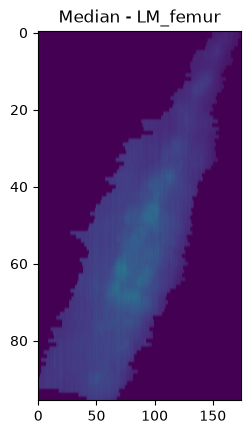

In [ ]:
# unmask the median
plot_sid = 6

ax = 0
temp = unmask_image_3d(medians[plot_sid], segment_masks==plot_sid, bounding_boxes[plot_sid])
plt.imshow(np.max(temp,ax), aspect=aspect_ratio[ax], vmin=100, vmax=250)
plt.title(f'Median - {segment_ids[plot_sid]}')
plt.show()

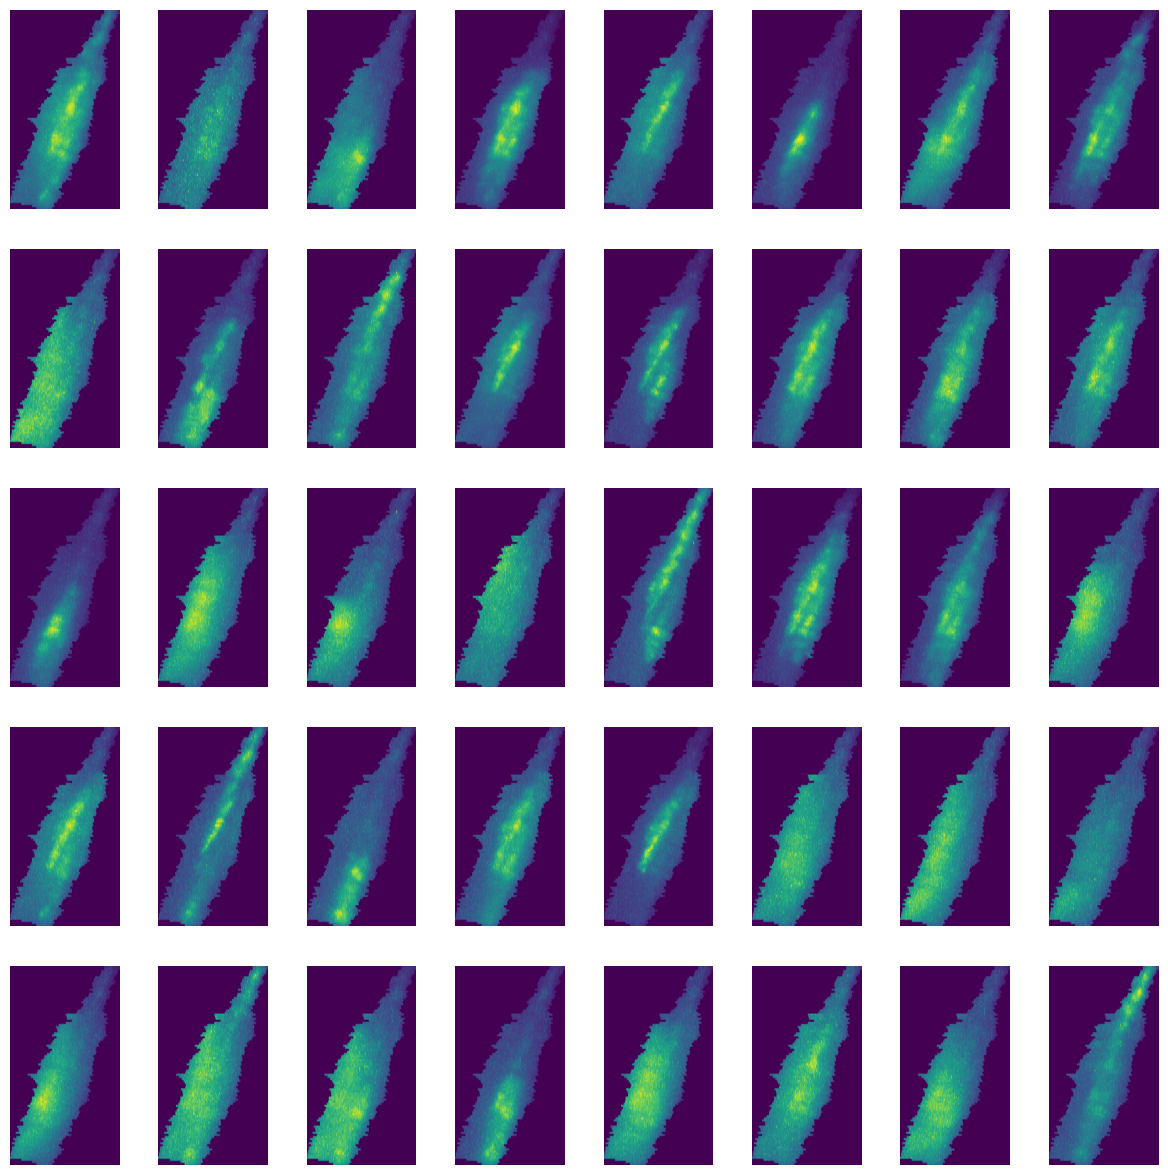

In [ ]:
axis = 0
fig,axes = plt.subplots(5,8,figsize=(15,15))
axes=axes.flatten()
for i, ax in enumerate(axes):
    temp = unmask_image_3d(segment_video_flat[plot_sid][selected_idx[plot_sid][i]], segment_masks==plot_sid, bounding_boxes[plot_sid])
    ax.imshow(np.max(temp,axis), aspect=aspect_ratio[axis], vmin=100)
    ax.axis('off')
plt.show()

### Test different numbers of components and check variance explained

In [ ]:
test_comp_n = False

In [ ]:
if test_comp_n:
    comp = list(range(6,24,2))
    var_explained = {}
    for sid in selected_segments:

        print('')
        print(f'Segment {sid}: {segment_ids[sid]}')
        frames_idx = selected_idx[sid]

        var_explained[sid] = []
        temp_comps = []
        spat_comps = []
        for n in comp:
            temp_comp, spatial_comp, _ = utils.fit_nmf(segment_video_flat_norm[sid], n, frames_idx)
            temp_comps.append(temp_comp)
            spat_comps.append(spatial_comp)
            var = utils.nmf_variance_explained(segment_video_flat_norm[sid][frames_idx], temp_comp[frames_idx], spatial_comp)
            var_explained[sid].append(var)
            print(f'   Done with n={n} - var={var}')


    # save var explained
    segment_numbers = sorted(var_explained.keys())
    variance_explained_array = np.array([var_explained[s] for s in segment_numbers])  # shape (n_segments, len(comp))
    segment_names = [segment_ids[s] for s in segment_numbers]

    var_h5_path = scape_path / 'segment_masked_video' / 'variance_explained.h5'

    with h5py.File(var_h5_path, 'a') as f:
        f.create_dataset('variance_explained', data=variance_explained_array)
        f.create_dataset('segment_numbers', data=segment_numbers)
        f.create_dataset('segment_names', data=segment_names, dtype=h5py.string_dtype(encoding='utf-8'))
        f.create_dataset('n_components', data=comp)



    # plot
    order = [7,4,12,13, 8,1,9,16, 6,3,11,15, 5,2,10,14]
    fig, axes = plt.subplots(4,4, figsize=(15,15))
    axes = axes.flatten()
    for i, sid in enumerate(order):
        try:
            axes[i].plot(comp, var_explained[sid])
            axes[i].set_xticks(comp)
            if i >= 12:
                axes[i].set_xlabel('# components')
            if i in [0,4,8,12]:
                axes[i].set_ylabel('Varience explained')
            axes[i].set_title(segment_ids[sid])
            axes[i].grid(True)
        except:
            print(f'no data yet for segment {sid}')
    plt.show()


### NMF to get components

In [6]:
n_comp = 12 # at or above elbow for all leg segments

In [ ]:
temp_comps = {}
spat_comps = {}
selected_idx ={}

for sid in segment_ids:
    print(sid, segment_ids[sid])

    # load data
    try:
        video_h5_path = scape_path / 'segment_masked_video' / f'{segment_ids[sid]}_masked_flattened_video.h5'
        with h5py.File(video_h5_path, 'r') as f:
            segment_video_flat = f['segment_video_flat'][:]
            selected_idx[sid] = f['selected_idx'][:]
            median = f['median'][:]
            segment_video_flat_norm = utils.diff_norm_frames(segment_video_flat, median)
            del segment_video_flat, median

    except Exception as e:
        print(e)

    print('  Data loaded - getting rois...')
    # run NMF to get components
    temp_comp, spatial_comp, _ = utils.fit_nmf(segment_video_flat_norm, n_comp, selected_idx[sid])
    temp_comps[sid] = temp_comp
    spat_comps[sid] = spatial_comp

1 LF_trochanter
  Data loaded - getting rois...
2 LF_tibia
  Data loaded - getting rois...
3 LF_femur
  Data loaded - getting rois...
4 LF_coxa
  Data loaded - getting rois...
5 LM_tibia
  Data loaded - getting rois...
6 LM_femur
  Data loaded - getting rois...
7 LM_coxa
  Data loaded - getting rois...
8 LM_trochanter
  Data loaded - getting rois...
9 RF_trochanter
  Data loaded - getting rois...
10 RF_tibia
  Data loaded - getting rois...
11 RF_femur
  Data loaded - getting rois...
12 RF_coxa
  Data loaded - getting rois...
16 RM_trochanter
  Data loaded - getting rois...
14 RM_tibia
  Data loaded - getting rois...
15 RM_femur
  Data loaded - getting rois...
13 RM_coxa
  Data loaded - getting rois...


### Calculate correlation between components

In [ ]:
selected_idx ={}
for sid in segment_ids:
    print(sid, segment_ids[sid])

    # load data
    try:
        video_h5_path = scape_path / 'segment_masked_video' / f'{segment_ids[sid]}_masked_flattened_video.h5'
        with h5py.File(video_h5_path, 'r') as f:
            selected_idx[sid] = f['selected_idx'][:]
            
    except Exception as e:
        print(e)

1 LF_trochanter
2 LF_tibia
3 LF_femur
4 LF_coxa
5 LM_tibia
6 LM_femur
7 LM_coxa
8 LM_trochanter
9 RF_trochanter
10 RF_tibia
11 RF_femur
12 RF_coxa
16 RM_trochanter
14 RM_tibia
15 RM_femur
13 RM_coxa


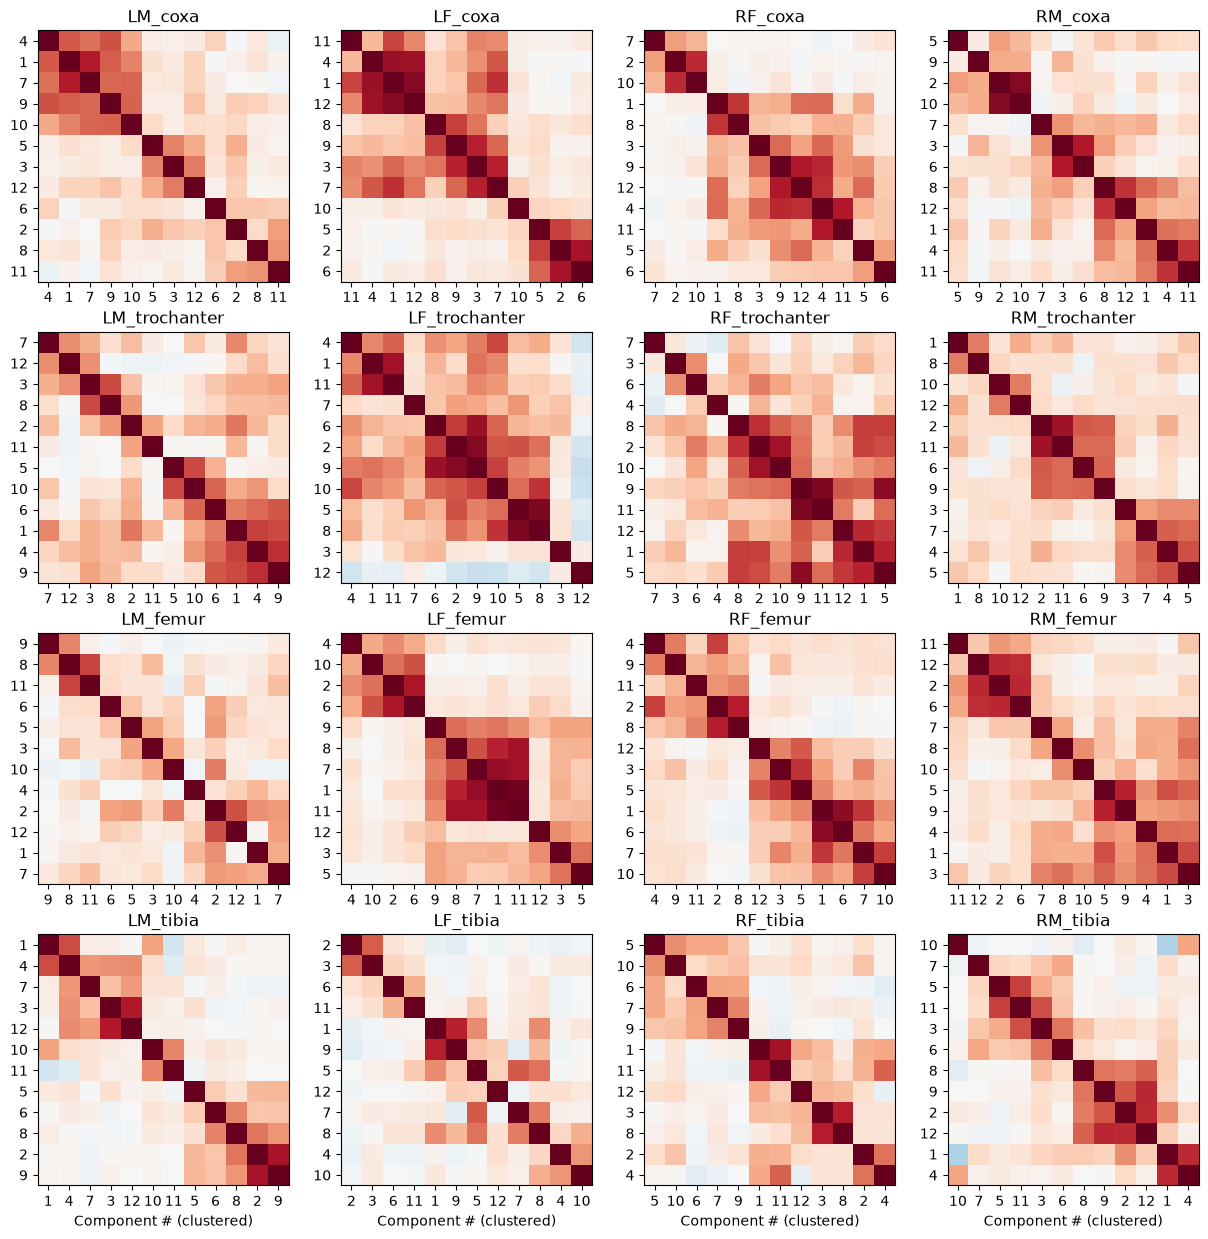

In [ ]:
# calculate correlation between components
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform

comp_order = {}

order = [7,4,12,13, 8,1,9,16, 6,3,11,15, 5,2,10,14]
fig, axes = plt.subplots(4,4, figsize=(15,15))
axes = axes.flatten()

for i, sid in enumerate(order):

    corr_matrix = np.corrcoef(temp_comps[sid][selected_idx[sid]], rowvar=False)

    # hierarchical-clustering leaf order, so similar components end up adjacent
    distance_matrix = 1 - corr_matrix
    np.fill_diagonal(distance_matrix, 0)  # exact zero diagonal (float roundoff)
    link = linkage(squareform(distance_matrix, checks=False), method='average')
    comp_order[sid] = dendrogram(link, no_plot=True)['leaves']

    corr_sorted = corr_matrix[np.ix_(comp_order[sid], comp_order[sid])]

    axes[i].imshow(corr_sorted, vmin=-0.75, vmax=0.75, cmap='RdBu_r')
    #axes[i].colorbar(label='Correlation')
    axes[i].set_xticks(range(len(comp_order[sid])), [o + 1 for o in comp_order[sid]])
    axes[i].set_yticks(range(len(comp_order[sid])), [o + 1 for o in comp_order[sid]])

    axes[i].set_title(segment_ids[sid])
    if i >= 12:
        axes[i].set_xlabel('Component # (clustered)')

plt.show()

In [13]:
from matplotlib.figure import Figure
def plot_temporal_components(W: np.ndarray,
                              timestamps: np.ndarray | None = None,
                              order: np.ndarray | list | None = None,
                              color: list | np.ndarray | None = None,
                              norm: bool = False,
                              fig: Figure | None = None,
                              legend: bool = False,
                              xlims: tuple | None = None) -> None:
    """Plot the temporal components as line plots, with options for ordering, coloring, and normalization."""

    if timestamps is None:
        timestamps = np.arange(W.shape[0])
    if order is None:
        order = np.arange(W.shape[1])
    else:
        utils._check_order(order, W.shape[1])

    if color is not None and len(color) == 1:
        color = color * len(order)

    blank = np.zeros(len(timestamps))
    if fig is None:
        plt.figure(figsize=(15, 5))

    for i, comp_i in enumerate(order):
        if np.isnan(comp_i):
            plt.plot(timestamps, blank - 1)
        else:
            temp = W[:, int(comp_i)]
            if norm:
                temp = (temp - np.min(temp)) / (np.max(temp) - np.min(temp))
            if color is not None:
                plt.plot(timestamps, temp + i, label=f'Comp {int(comp_i+1)}', linewidth=1, color=color[i])
            else:
                plt.plot(timestamps, temp + i, label=f'Comp {int(comp_i+1)}', linewidth=1)

    plt.ylim(-0.5, len(order) + 0.5)
    plt.yticks(np.arange(len(order)), [f'Comp {int(comp_i+1)}' if not np.isnan(comp_i) else '' for comp_i in order])
    if timestamps is not None:
        plt.xlabel('Time (s)')
    else:
        plt.xlabel('Frames')
    plt.ylabel('Component Activation')
    plt.title('Temporal Components from NMF')
    if legend:
        plt.legend()

    if xlims is not None:
        plt.xlim(xlims)
    else:
        plt.xlim(timestamps[0], timestamps[-1])

    if fig is None:
        plt.show()

LF_trochanter


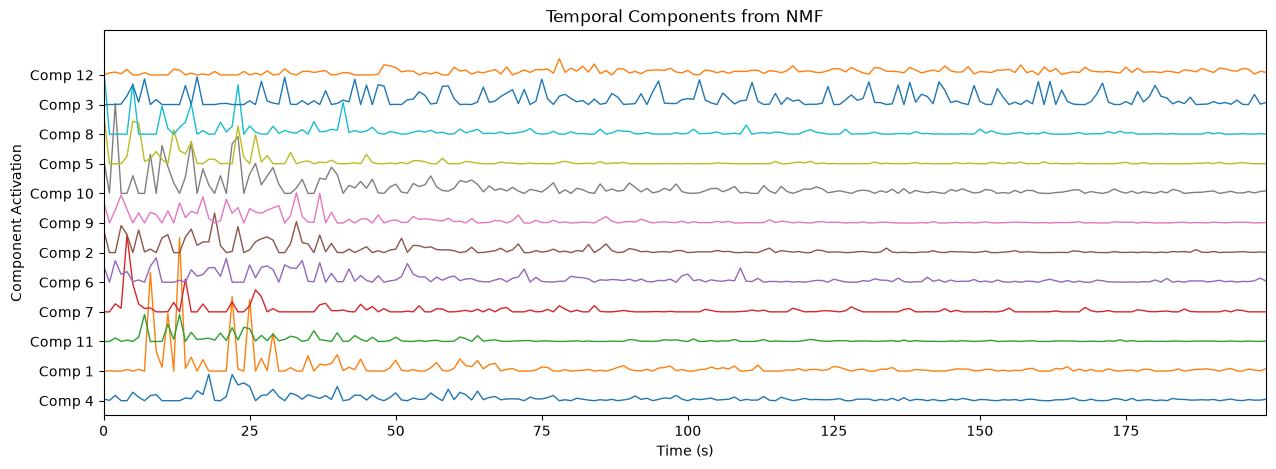

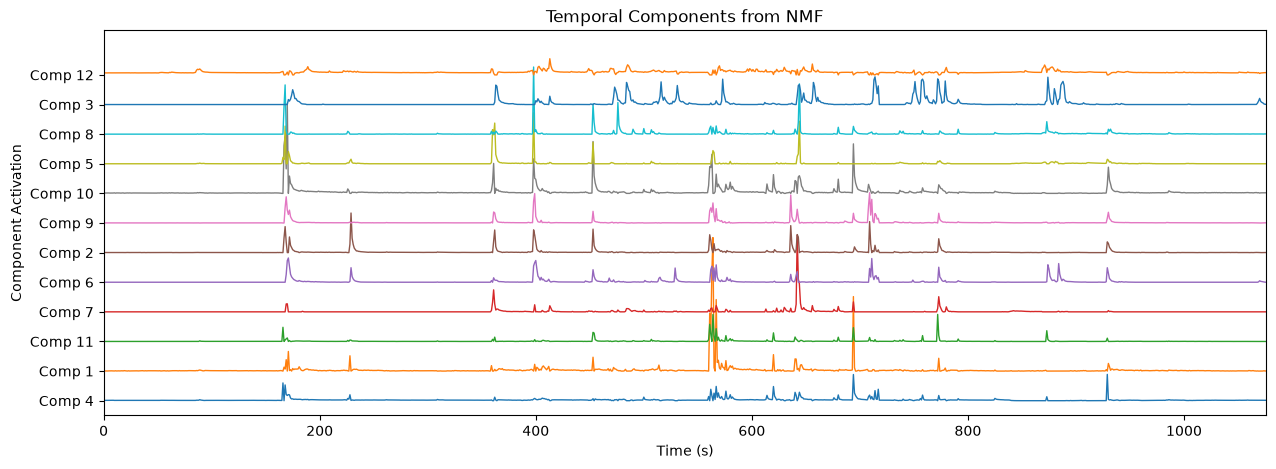

In [ ]:
plot_sid = 1
print(segment_ids[plot_sid])
plot_temporal_components(temp_comps[plot_sid][selected_idx[plot_sid]],order=comp_order[plot_sid])
plot_temporal_components(temp_comps[plot_sid],order=comp_order[plot_sid])

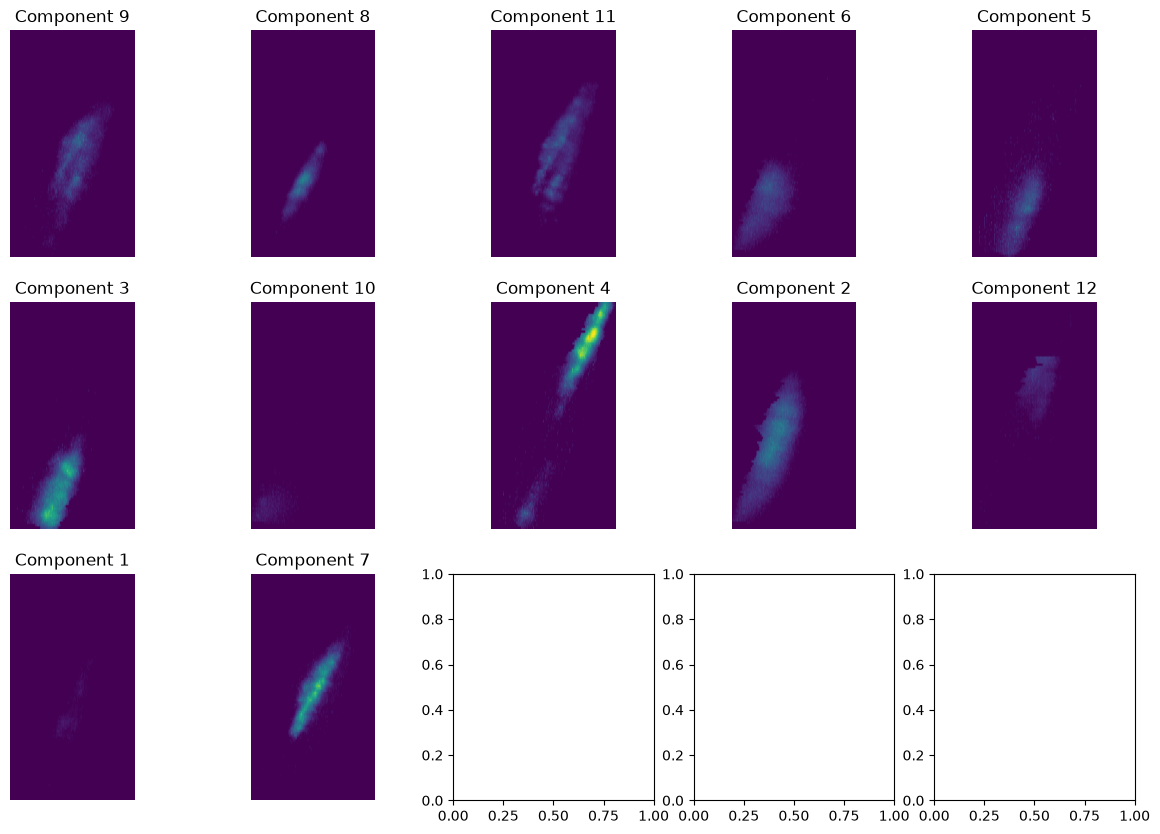

In [ ]:
ax = 0
fig,axes = plt.subplots(3,5,figsize=(15,10))
axes=axes.flatten()
for i in range(spat_comps[plot_sid].shape[0]):
    temp = unmask_image_3d(spat_comps[plot_sid][comp_order[plot_sid]][i], segment_masks==plot_sid, bounding_boxes[plot_sid])
    axes[i].imshow(np.max(temp,ax), aspect=aspect_ratio[ax], vmin=0.075, vmax=0.5)
    axes[i].axis('off')
    axes[i].set_title(f'Component {comp_order[plot_sid][i]+1}')
plt.show()

### Assign a single component (or none) to each pixel
Each voxel is assigned to the component that they have the max value for but only if above a minimal threshold (to exclude background). Then keep only the biggest contiguous roi

In [ ]:
# assign a single component to each pixel (max + thresh)
thresh = 0.075

pixel_ids = {}

for sid in segment_ids:
    spatial_comp = spat_comps[sid]
    pixel_ids[sid] = np.zeros(spatial_comp.shape[1],)
    for pix in range(spatial_comp.shape[1]):
        max_id = np.argmax(spatial_comp[:, pix])
        if spatial_comp[max_id, pix] > thresh:
            pixel_ids[sid][pix] = max_id + 1

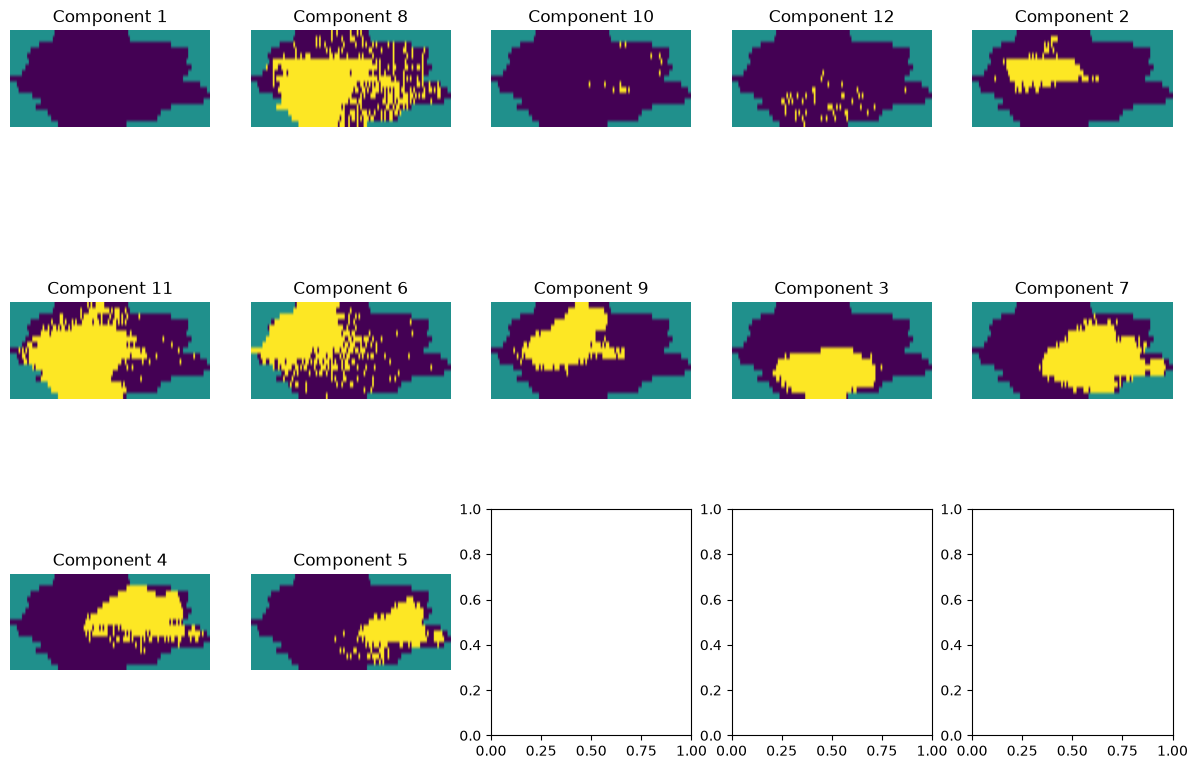

In [ ]:
# plot spatial components as masks
ax = 0
plot_sid = 16
segment_mask = segment_masks == plot_sid
segment_mask_proj = np.max(segment_mask[bounding_boxes[plot_sid]], axis=ax)

fig,axes = plt.subplots(3,5,figsize=(15,10))
axes=axes.flatten()
for i, comp_id in enumerate(comp_order[plot_sid]):
    temp = unmask_image_3d(pixel_ids[plot_sid]==comp_id+1, segment_mask, bounding_boxes[plot_sid])
    temp_proj = np.max(temp,ax)
    display = np.where(segment_mask_proj, temp_proj, 0.5)  # outside the segment mask -> 0.5
    axes[i].imshow(display, aspect=aspect_ratio[ax], vmin=0, vmax=1)
    axes[i].axis('off')
    axes[i].set_title(f'Component {comp_id+1}')
plt.show()

In [64]:
# keep only the biggest contigous mass

def keep_largest_component(mask_3d: np.ndarray, warn_ratio: float = 0.5, min_kept_pixels: int = 0) -> np.ndarray:
    """
    Keep only the largest connected component of a 3D boolean mask,
    zeroing out every other connected component.

    Parameters
    ----------
    mask_3d : ndarray of bool
        Mask to filter.

    warn_ratio : float
        Print a warning if the second-largest connected component's
        size, as a fraction of the largest one's, exceeds this - i.e.
        the choice of "the" component is ambiguous.

    Returns
    -------
    ndarray of bool
        `mask_3d` restricted to its largest connected component (all
        `False` if `mask_3d` has no `True` voxels).
    """
    if not np.any(mask_3d):
        return mask_3d

    labeled, num_features = ndimage.label(mask_3d)
    sizes = ndimage.sum(mask_3d, labeled, index=np.arange(1, num_features + 1))
    order = np.argsort(sizes)[::-1]
    largest_label = order[0] + 1
    largest_size = sizes[order[0]]

    if num_features > 1:
        second_size = sizes[order[1]]
        if second_size / largest_size > warn_ratio and largest_size >= min_kept_pixels: #supressed warning if largest < min, as it will be excluded anyways
            print(f'    Warning: second-largest mass ({second_size:.0f} voxels) is not much '
                  f'smaller than the largest ({largest_size:.0f} voxels) - ratio = '
                  f'{second_size / largest_size:.2f}')

    return labeled == largest_label


# pixel_id encodes component ids as 1..n_components, with 0 = background/unassigned (see above)
min_kept_pixels = 500
pixel_ids_filtered = {}

for sid in segment_ids:
    print(f'{sid}: {segment_ids[sid]}')
    segment_mask = segment_masks == sid
    pixel_id = pixel_ids[sid]
    n_components = spat_comps[sid].shape[0]
    pixel_id_filtered = pixel_id.copy()  # discarded/removed pixels are set back to 0 (background)

    for comp_id in range(1, n_components + 1):
        comp_pixel_mask = pixel_id == comp_id
        n_pixels = int(comp_pixel_mask.sum())
        if n_pixels == 0:
            print(f'  Component {comp_id}: no pixels assigned, skipping')
            continue

        comp_mask_3d = unmask_image_3d(comp_pixel_mask, segment_mask).astype(bool)
        largest_mask_3d = keep_largest_component(comp_mask_3d, min_kept_pixels=min_kept_pixels)

        kept_flat = largest_mask_3d[segment_mask]
        n_kept = int(kept_flat.sum())

        if n_kept <= min_kept_pixels:
            pixel_id_filtered[comp_pixel_mask] = 0
            print(f'  Component {comp_id}: {n_pixels} pixels -> largest mass only {n_kept} pixels '
                  f'(<= {min_kept_pixels}), removing entire component')
            print('    ----')
            continue

        discarded = comp_pixel_mask & ~kept_flat
        pixel_id_filtered[discarded] = 0

        print(f'  Component {comp_id}: {n_pixels} pixels -> kept {n_kept}, '
              f'discarded {int(discarded.sum())} isolated pixels')
        
    pixel_ids_filtered[sid] = pixel_id_filtered

1: LF_trochanter
  Component 1: 4 pixels -> largest mass only 1 pixels (<= 500), removing entire component
    ----
  Component 2: 4567 pixels -> kept 4507, discarded 60 isolated pixels
  Component 3: 1869 pixels -> kept 1864, discarded 5 isolated pixels
  Component 4: 3492 pixels -> kept 2527, discarded 965 isolated pixels
  Component 5: 5614 pixels -> kept 5489, discarded 125 isolated pixels
  Component 6: 2872 pixels -> kept 2863, discarded 9 isolated pixels
  Component 7: 1033 pixels -> kept 685, discarded 348 isolated pixels
  Component 8: 1738 pixels -> kept 1704, discarded 34 isolated pixels
  Component 9: 3462 pixels -> kept 3378, discarded 84 isolated pixels
  Component 10: 641 pixels -> largest mass only 263 pixels (<= 500), removing entire component
    ----
  Component 11: 5812 pixels -> kept 2953, discarded 2859 isolated pixels
  Component 12: 130 pixels -> largest mass only 18 pixels (<= 500), removing entire component
    ----
2: LF_tibia
  Component 1: 136 pixels -> lar

RF_trochanter


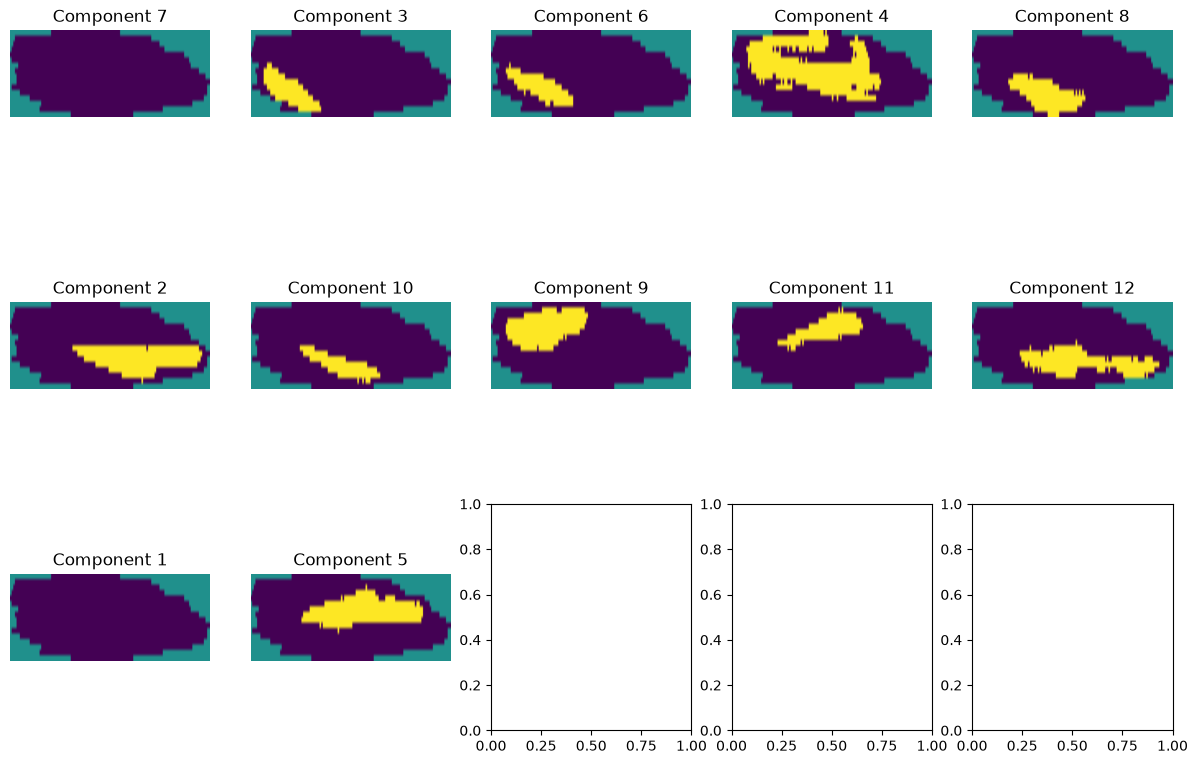

In [88]:
# plot spatial components as masks
ax = 0
plot_sid = 9
print(segment_ids[plot_sid])

segment_mask = segment_masks == plot_sid
segment_mask_proj = np.max(segment_mask[bounding_boxes[plot_sid]], axis=ax)

fig,axes = plt.subplots(3,5,figsize=(15,10))
axes=axes.flatten()
for i, comp_id in enumerate(comp_order[plot_sid]):
    temp = unmask_image_3d(pixel_ids_filtered[plot_sid]==comp_id+1, segment_mask, bounding_boxes[plot_sid])
    temp_proj = np.max(temp,ax)
    display = np.where(segment_mask_proj, temp_proj, 0.5)  # outside the segment mask -> 0.5
    axes[i].imshow(display, aspect=aspect_ratio[ax], vmin=0, vmax=1)
    axes[i].axis('off')
    axes[i].set_title(f'Component {comp_id+1}')
plt.show()

In [66]:
# save pixel_id_filtered as a tif, to load/edit in napari (see edit_labels_napari.py)

def save_labels_as_tif(labels, mask, out_path):
    labels_3d = unmask_image_3d(labels, mask).astype(np.uint16)

    tifffile.imwrite(out_path, labels_3d)
    print(f'Saved {out_path}, shape {labels_3d.shape}, '
        f'{len(np.unique(labels_3d)) - 1} components')

nmf_seg_folder = scape_path / 'NMF_segmentation'
nmf_seg_folder.mkdir(parents=True, exist_ok=True)

for sid in segment_ids:
    out_path = nmf_seg_folder / f'{segment_ids[sid]}_NMF_components_{n_comp}.tif'
    save_labels_as_tif(pixel_ids_filtered[sid], segment_masks == sid, out_path)

Saved /mnt/labserver/data/MA/SCAPE/20260716_MA12_pupa-P15/sample2_combined/NMF_segmentation/LF_trochanter_NMF_components_12.tif, shape (336, 261, 1000), 9 components
Saved /mnt/labserver/data/MA/SCAPE/20260716_MA12_pupa-P15/sample2_combined/NMF_segmentation/LF_tibia_NMF_components_12.tif, shape (336, 261, 1000), 10 components
Saved /mnt/labserver/data/MA/SCAPE/20260716_MA12_pupa-P15/sample2_combined/NMF_segmentation/LF_femur_NMF_components_12.tif, shape (336, 261, 1000), 12 components
Saved /mnt/labserver/data/MA/SCAPE/20260716_MA12_pupa-P15/sample2_combined/NMF_segmentation/LF_coxa_NMF_components_12.tif, shape (336, 261, 1000), 11 components
Saved /mnt/labserver/data/MA/SCAPE/20260716_MA12_pupa-P15/sample2_combined/NMF_segmentation/LM_tibia_NMF_components_12.tif, shape (336, 261, 1000), 11 components
Saved /mnt/labserver/data/MA/SCAPE/20260716_MA12_pupa-P15/sample2_combined/NMF_segmentation/LM_femur_NMF_components_12.tif, shape (336, 261, 1000), 10 components
Saved /mnt/labserver/data

### Group components by muscle

In [ ]:
muscles_all = {'LF_femur':
               {'FeTi_ext':           [2,  [4,2,6,10]],      # light blue
                'FeTi_lat-acc-flex':  [10, [12,3]],          # red
                'FeTi_ltm':           [20, [9]],             # pink
                'FeTi_flex':          [5,  [7,8,5,1,11]],    # dark blue
                'FeTi_med-acc-flex':  [6,  []],              # green
                },             
            'RF_femur':
               {'FeTi_ext':      [2,  [8,2,4,9,11]],    
                'FeTi_lat-acc':  [10, [5]],             
                'FeTi_ltm':      [20, [12]], 
                'FeTi_flex':     [5,  [6,7,3,1,10]],
                'FeTi_med-acc':  [6,  []],
                },
            'LF_coxa':
               {'CoTr_flex':     [32, [4,1,3,9,7,12]],      # orange
                'CoTr_ext':      [20, [5,2,6]],             # pink
                'CoTr_acc-ext':  [5,  []], # with previous  # dark blue
                'CoTr_acc-flex': [2,  [8]],                 # light blue
                'ThCo_rot':      [7,  [10]],                # white/grey
               },
            'RF_coxa':
               {'CoTr_flex':     [32, [3,8,11,4,9,12,5]],   # orange
                'CoTr_ext':      [20, [7,2]],               # pink
                'CoTr_acc-ext':  [5,  []], # with previous  # dark blue
                'CoTr_acc-flex': [2,  [6]],                 # light blue
                'ThCo_rot':      [7,  [10]],               # white/grey
               },
            'LF_tibia':
               {'TiTa_acc-heart_p1': [10, [9,7,8]],     # red
                'TiTa_acc-heart_p2': [19, [4,12,10]],   # red-ish
                'TiTa_ltm':          [6,  [2,3]],       # green
                'TiTa_2':            [4,  [11,6]],      # purple
                'TiTa_3':            [32, []],          # orange
                'TiTa_4':            [20, []],          # pink
                },
            'RF_tibia':
               {'TiTa_acc-heart_p1': [10, [11,12,1,4]],
                'TiTa_acc-heart_p2': [19, [8,3]],
                'TiTa_ltm':          [6,  [7,9]],
                'TiTa_2':            [4,  [10,5,6]],
                'TiTa_3':            [32, []],
                'TiTa_4':            [20, []],
                },
            'LF_trochanter':
               {'TrFe_1': [2,  [3]],        # light blue
                'TrFe_2': [4,  [4]],        # purple
                'TrFe_3': [6,  [6,9,2]],    # green
                'TrFe_4': [9,  [5,8,7]],      # yellow
                'TrFe_5': [10, [11]],       # red
                
                },
            'RF_trochanter':
               {'TrFe_1': [2,  [3]],
                'TrFe_2': [4,  [6]],
                'TrFe_3': [6,  [8,10,2]],
                'TrFe_4': [9,  [5,9,11,4]],
                'TrFe_5': [10, [12]],
                },

            'LM_femur':
               {'FeTi_ext':           [2,  [12,2,6]],        # light blue
                'FeTi_lat-acc-flex':  [10, []],              # red
                'FeTi_ltm':           [20, [5]],             # pink
                'FeTi_flex':          [5,  [3,7,11,4,8,9]],  # dark blue
                'FeTi_med-acc-flex':  [6,  []],              # green
                },             
            'RM_femur':
               {'FeTi_ext':      [2,  [2,6,12]],    
                'FeTi_lat-acc':  [10, []],             
                'FeTi_ltm':      [20, [7]], 
                'FeTi_flex':     [5,  [10,5,8,3,9,1,4]],
                'FeTi_med-acc':  [6,  []],
                },
            'LM_coxa':
               {'CoTr_1-2':      [4,  [4]],         # purple
                'ThCo_3':        [6,  [6]],         # green
                'ThCo_4':        [9,  [2]],         # yellow
                'ThTr_1':        [2,  [5,3,12]],    # light blue
                'ThTr_4':        [10, [7,9,1,10]],  # red
                },    
            'RM_coxa':
               {'CoTr_1-2':      [4,  [11]],        
                'ThCo_3':        [6,  [5]],              
                'ThCo_4':        [9,  [2,9,10]],              
                'ThTr_1':        [2,  [3,6,7]],            
                'ThTr_4':        [10, [4,1,12,8]],  
                }, 
            'LM_tibia':
               {'TiTa_acc-heart_p1': [10, [4,10,11]],   # red
                'TiTa_acc-heart_p2': [19, [12,7]],      # red-ish
                'TiTa_ltm':          [6,  [5,3]],       # green
                'TiTa_2':            [4,  [6,8,2,9]],   # purple
                'TiTa_3':            [32, []],          # orange
                'TiTa_4':            [20, []],          # pink
                },
            'RM_tibia':
               {'TiTa_acc-heart_p1': [10, [8,4,10,1]],
                'TiTa_acc-heart_p2': [19, [2,12]],
                'TiTa_ltm':          [6,  [9]],
                'TiTa_2':            [4,  [6,3,11,5,7]],
                'TiTa_3':            [32, []],
                'TiTa_4':            [20, []],
                },
            'LM_trochanter':
               {'TrFe_1': [2,  [3]],        # light blue
                'TrFe_3': [6,  [8,7,2]],    # green
                'TrFe_4': [4,  [4,6,9]],    # purple
                },
            'RM_trochanter':
               {'TrFe_1': [2,  [3]],
                'TrFe_3': [6,  [7,4,5]],
                'TrFe_4': [4,  [9,6,11,2,8]],
                },
            }


for sid in segment_ids:
    if segment_ids[sid] in muscles_all.keys():

        out_path = nmf_seg_folder / f'{segment_ids[sid]}_NMF_components_{n_comp}_joined.tif'
        if out_path.exists():
            continue

        print(segment_ids[sid])
    

        pixel_id_filtered = pixel_ids_filtered[sid]
        pixel_id_filtered_join = np.zeros_like(pixel_id_filtered)
        for muscle, ids in muscles_all[segment_ids[sid]].items():
            new_id = ids[0] # just to match color to reference in webknonossos
            for old_id in ids[1]:
                pixel_id_filtered_join[pixel_id_filtered==old_id] = new_id

        save_labels_as_tif(pixel_id_filtered_join, segment_masks==sid, out_path)

LM_trochanter
Saved /mnt/labserver/data/MA/SCAPE/20260716_MA12_pupa-P15/sample2_combined/NMF_segmentation/LM_trochanter_NMF_components_12_joined.tif, shape (336, 261, 1000), 3 components
RF_trochanter
Saved /mnt/labserver/data/MA/SCAPE/20260716_MA12_pupa-P15/sample2_combined/NMF_segmentation/RF_trochanter_NMF_components_12_joined.tif, shape (336, 261, 1000), 5 components
RM_trochanter
Saved /mnt/labserver/data/MA/SCAPE/20260716_MA12_pupa-P15/sample2_combined/NMF_segmentation/RM_trochanter_NMF_components_12_joined.tif, shape (336, 261, 1000), 3 components


In [130]:
# save a tif image with all labels for all muscles
import json
import re

def merge_trochanter_muscles(muscle_dict: dict) -> dict:
    """
    Join all 'TrFe_N' entries of a segment's muscle dict (see
    `muscles_all`) into a single 'TrFe' entry, merging their
    (raw, pre-grouping) NMF component ids. Other muscles are passed
    through unchanged.
    """
    merged = {}
    trfe_ids = []
    for muscle, ids in muscle_dict.items():
        if muscle.startswith('TrFe'):
            trfe_ids.extend(ids[1])
        else:
            merged[muscle] = ids
    if trfe_ids:
        merged['TrFe'] = [None, trfe_ids]
    return merged


# expand our shorthand muscle-name tokens to match the reference's naming
# (compound entries first, so e.g. 'lat-acc' expands before a hypothetical
# bare 'lat' rule would get a chance to)
MUSCLE_NAME_ABBREVIATIONS = {
    'ext': 'extensor',
    'flex': 'flexor',
    'ltm': 'long-tendon',        # long-tendon muscle
    'acc-heart': 'acc-heart-muscle',
    'lat-acc': 'lateral-acc-flexor',
    'med-acc': 'medial-acc-flexor',
}


def expand_muscle_name(name: str) -> str:
    """
    Expand shorthand tokens in a muscle name to match the reference's
    naming convention (see `MUSCLE_NAME_ABBREVIATIONS`). Tokens are
    only replaced as standalone '-'/'_'-delimited words, longest first,
    so e.g. 'lat-acc' expands as a whole rather than leaving a stray
    'acc'.
    """
    for abbr, full in sorted(MUSCLE_NAME_ABBREVIATIONS.items(), key=lambda kv: -len(kv[0])):
        name = re.sub(rf'(?<![A-Za-z]){re.escape(abbr)}(?![A-Za-z])', full, name)
    return name


pixel_id_all = np.zeros_like(segment_masks)
muscle_id = {}

new_id = 0
for sid in segment_ids:
    if segment_ids[sid] not in muscles_all:
        continue

    pixel_id_filtered = pixel_ids_filtered[sid]
    segment_mask = segment_masks == sid
    muscles_for_segment = merge_trochanter_muscles(muscles_all[segment_ids[sid]])

    for muscle, ids in muscles_for_segment.items():
        new_id += 1
        muscle_id[new_id] = f'{segment_ids[sid]}_{expand_muscle_name(muscle)}'

        # ids[1]: this segment's own (raw, pre-grouping) NMF component ids for this muscle
        muscle_pixel_mask = np.isin(pixel_id_filtered, ids[1])
        muscle_mask_3d = unmask_image_3d(muscle_pixel_mask, segment_mask).astype(bool)
        pixel_id_all[muscle_mask_3d] = new_id

out_path = nmf_seg_folder / 'all_muscles_NMF_components.tif'
tifffile.imwrite(out_path, pixel_id_all.astype(np.uint16))
print(f'Saved {out_path}, shape {pixel_id_all.shape}, {new_id} muscles')

ids_path = nmf_seg_folder / 'all_muscles_NMF_components_ids.json'
with open(ids_path, 'w') as f:
    json.dump(muscle_id, f, indent=2)
print(f'Saved {ids_path}')

Saved /mnt/labserver/data/MA/SCAPE/20260716_MA12_pupa-P15/sample2_combined/NMF_segmentation/all_muscles_NMF_components.tif, shape (336, 261, 1000), 68 muscles
Saved /mnt/labserver/data/MA/SCAPE/20260716_MA12_pupa-P15/sample2_combined/NMF_segmentation/all_muscles_NMF_components_ids.json


In [9]:
# minimal reload after a kernel restart - just enough to re-run the
# reference-labels save cell below, skipping the heavy NMF/video pipeline
from pathlib import Path
import numpy as np
import tifffile
import json

main_path = Path('/mnt/labserver/data/MA/SCAPE/')
scape_path = main_path / '20260716_MA12_pupa-P15/sample2_combined'
nmf_seg_folder = scape_path / 'NMF_segmentation'

In [10]:
import sys
sys.path.append(str(Path('/home/azcorra/git/Devel/Pupa_muscle_imaging/referenceMaps')))
from webknossos import load_labels, load_segment_groups



reference_path = Path('/mnt/labserver/data/MA/CT_scans_PIXE/2026-06-16_Webknossos_muscle_leg_tracing_pupa_annotations/RF-RM Leg muscles in pupa')
labels_path = reference_path / 'labels'

# Load reference labels
labels, id_to_name = load_labels(labels_path) # takes about 1 min

# 'thorax' included: the real data grouped thorax and coxa muscles together
# as 'coxa', so the reference needs those to resolve to a group too (see
# GROUP_NAME_MERGES below, which then folds 'thorax' into 'coxa')
segment_groups = load_segment_groups(labels_path, ['RF', 'RM'], ['thorax', 'coxa','trochanter','femur','tibia'])

In [11]:
# save the webknossos reference labels as a tif image and matching json, same format as above
import re

# known typos/duplicates in the raw webknossos segment names:
# - id 31 is missing its 'RF_' prefix and uses inconsistent style vs its
#   siblings (ids 27-30, all 'RF_TiTa_long-tendon_pN')
# - ids 24/25 are BOTH named 'RF_FeTi-medial-acc-flexor_p2' (hyphen typo +
#   duplicate part number) - 24 becomes _p1 so they form a proper p1/p2 pair
# - id 78 'RM_FeTi-lateral-acc-flexor' has the same hyphen typo
# - id 73 'RM_FeTi_long_tendon' uses an underscore instead of the hyphen
#   used everywhere else ('long-tendon')
# - id 50 'RF_ThCo_sternal-anterior-rotator' is the real data's 'ThCo_rot'
# - id 80 'RM_TiTa_acc-heart-muscle_p3' is renamed to _p2, joining it with
#   id 79 into one muscle (real data only identifies 2 parts here, not 3)
ID_TO_NAME_FIXES = {
    31: 'RF_TiTa_long-tendon_p3',
    24: 'RF_FeTi_medial-acc-flexor_p1',
    25: 'RF_FeTi_medial-acc-flexor_p2',
    78: 'RM_FeTi_lateral-acc-flexor',
    73: 'RM_FeTi_long-tendon',
    50: 'RF_ThCo_rot',
    80: 'RM_TiTa_acc-heart-muscle_p2',
}
id_to_name_fixed = {**id_to_name, **ID_TO_NAME_FIXES}

# the real data grouped thorax and coxa muscles together as 'coxa'
GROUP_NAME_MERGES = {'thorax': 'coxa'}

# muscles whose p1..pN parts should stay separate (matching how the real
# data itself keeps them split) rather than being merged into one, unlike
# e.g. FeTi_extensor_p1..p8 or TiTa_long-tendon_p1..p9, which the real data
# fully merges into a single muscle
KEEP_PARTS_SEPARATE = {'TiTa_acc-heart-muscle'}

# CoTr_1/CoTr_2 (RM_coxa) are deliberately NOT merged, even though the real
# data merges them into one 'CoTr_1-2' - left as a known, accepted mismatch


def resolve_group_name(group_name: str) -> str:
    """Fold 'thorax' groups into 'coxa' (see GROUP_NAME_MERGES)."""
    side_leg, segment = group_name.split('_', 1)
    segment = GROUP_NAME_MERGES.get(segment, segment)
    return f'{side_leg}_{segment}'


# build each segment's muscle name: drop '?' (annotator uncertainty), and
# merge '_pN' parts of the same muscle into one shared name (except
# KEEP_PARTS_SEPARATE), matching how the real data groups its own components
muscle_name_by_id = {}
for seg_id, group_name in segment_groups.items():
    full_name = id_to_name_fixed.get(seg_id)
    if full_name is None:
        continue
    side_leg = group_name.split('_')[0]
    if not full_name.startswith(side_leg + '_'):
        print(f'  Warning: {full_name!r} (id {seg_id}) does not start with {side_leg!r}, skipping')
        continue
    muscle_name = full_name[len(side_leg) + 1:].replace('?', '')
    base_name = re.sub(r'_p\d+$', '', muscle_name)
    if base_name not in KEEP_PARTS_SEPARATE:
        muscle_name = base_name
    muscle_name_by_id[seg_id] = f'{resolve_group_name(group_name)}_{muscle_name}'

# merge same-named ids (originally separate parts) into one new id each.
# relabel via a single vectorized lookup table (indexed by raw webknossos
# id -> new id) instead of one np.isin(labels, ...) scan per muscle - labels
# has ~1.7 billion voxels, so ~65 separate full-array scans was taking ~30 min;
# one vectorized lookup pass takes a few seconds
name_to_new_id = {name: i + 1 for i, name in enumerate(sorted(set(muscle_name_by_id.values())))}
reference_id_to_name = {new_id: name for name, new_id in name_to_new_id.items()}

lookup = np.zeros(int(labels.max()) + 1, dtype=np.uint16)
for seg_id, name in muscle_name_by_id.items():
    lookup[seg_id] = name_to_new_id[name]
reference_labels = lookup[labels]

print('Saving...')
out_path = nmf_seg_folder / 'webknossos_reference_labels_original.tif'
tifffile.imwrite(out_path, reference_labels.astype(np.uint16))
print(f'Saved {out_path}, shape {reference_labels.shape}, {len(name_to_new_id)} muscles')

ids_path = nmf_seg_folder / 'webknossos_reference_labels_ids.json'
with open(ids_path, 'w') as f:
    json.dump(reference_id_to_name, f, indent=2)
print(f'Saved {ids_path}, {len(reference_id_to_name)} named muscles '
      f'(from {len(id_to_name)} raw webknossos segments)')

Saving...
Saved /mnt/labserver/data/MA/SCAPE/20260716_MA12_pupa-P15/sample2_combined/NMF_segmentation/webknossos_reference_labels_original.tif, shape (1312, 1184, 1120), 50 muscles
Saved /mnt/labserver/data/MA/SCAPE/20260716_MA12_pupa-P15/sample2_combined/NMF_segmentation/webknossos_reference_labels_ids.json, 50 named muscles (from 98 raw webknossos segments)


In [ ]:
# check whether every R-side real-data muscle name has an exact match in the reference
# (only R-side, since the reference only has RF/RM)
real_names_R = {name for name in muscle_id.values() if name.startswith(('RF_', 'RM_'))}
reference_names_R = set(reference_id_to_name.values())

missing = sorted(real_names_R - reference_names_R)
print(f'{len(real_names_R)} R-side muscle names in the real data, '
      f'{len(missing)} with no exact match in the reference:')
for name in missing:
    print(' ', name)